# 1. Размер датасета, пропуски и дубликаты

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/IMDB Dataset.csv")

print(f"Строк: {len(df):,}")
print(f"Столбцов: {df.shape[1]}")
print("Колонки:", df.columns.tolist())
print("Пропуски по колонкам:")
display(df.isna().sum().to_frame("Пропуски"))

reviews = df.dropna(subset=["review"]).copy()
blank = reviews["review"].str.strip().eq("")
print("Пустых отзывов без учёта пропусков:", blank.sum())
reviews = reviews.loc[~blank].copy()

print("Повторных строк сверх первого вхождения:", df.duplicated().sum())
print("Повторных текстов сверх первого вхождения:", reviews["review"].duplicated().sum())

labels_per_review = reviews.groupby("review")["sentiment"].nunique()
print("Уникальных текстов с разными метками:", labels_per_review.gt(1).sum())

Строк: 50,000
Столбцов: 2
Колонки: ['review', 'sentiment']
Пропуски по колонкам:


,Пропуски
review,0
sentiment,0


Пустых отзывов без учёта пропусков: 0
Повторных строк сверх первого вхождения: 418
Повторных текстов сверх первого вхождения: 418
Уникальных текстов с разными метками: 0


# 2. Баланс классов и длина отзывов

In [2]:
counts = df["sentiment"].value_counts(dropna=False)
balance = pd.DataFrame({
    "Количество": counts,
    "Доля, %": (counts / len(df) * 100).round(2),
})
display(balance)

clean_text = reviews["review"].str.replace(r"<[^>]+>", " ", regex=True)
reviews["word_count"] = clean_text.str.split().str.len()

length_stats = (
    reviews.groupby("sentiment")["word_count"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95])
    .round(1)
    .rename(columns={"50%": "Медиана"})
)
display(length_stats)

,Количество,"Доля, %"
sentiment,,
positive,25000,50.0
negative,25000,50.0


,count,mean,std,min,25%,Медиана,75%,95%,max
sentiment,,,,,,,,,
negative,25000.0,227.1,163.2,4.0,127.0,172.0,275.0,567.0,1491.0
positive,25000.0,230.6,175.8,10.0,124.0,171.0,280.0,602.0,2459.0


#3. Отчётные графики

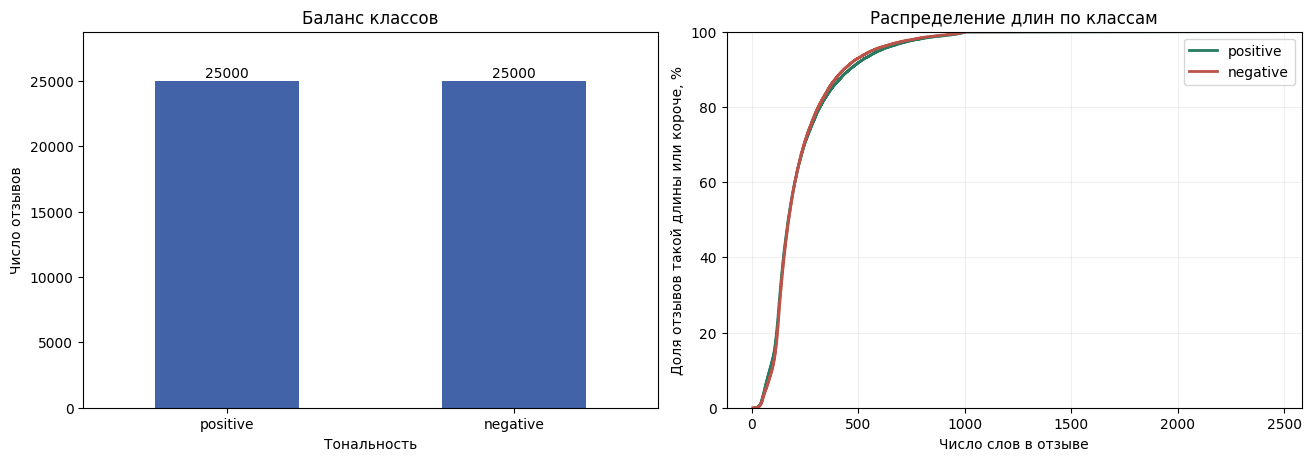

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")

balance["Количество"].plot.bar(ax=axes[0], color="#4263a8", rot=0)
axes[0].set(title="Баланс классов", xlabel="Тональность", ylabel="Число отзывов")
axes[0].bar_label(axes[0].containers[0])
axes[0].margins(y=0.15)

for label, color in [("positive", "#287a60"), ("negative", "#bb5349")]:
    lengths = reviews.loc[reviews["sentiment"].eq(label), "word_count"]
    lengths = lengths.sort_values().reset_index(drop=True)
    cumulative = (lengths.index + 1) / len(lengths) * 100
    axes[1].plot(lengths, cumulative, label=label, color=color, linewidth=2)

axes[1].set(
    title="Распределение длин по классам",
    xlabel="Число слов в отзыве",
    ylabel="Доля отзывов такой длины или короче, %",
    ylim=(0, 100),
)
axes[1].legend()
axes[1].grid(alpha=0.2)

fig.savefig("imdb_eda.png", dpi=180, bbox_inches="tight")
plt.show()

### Вывод

В исходном датасете 50 000 отзывов и два столбца - `review` с текстом и `sentiment` с меткой тональности. Классы сбалансированы: по 25 000 положительных и отрицательных отзывов. Пропусков и пустых текстов нет.

Обнаружено 418 повторных строк сверх первого вхождения (0,84% датасета). Одинаковых текстов с разными метками нет. После удаления точных повторов останется 49 582 отзыва. Удаление нужно провести до разбиения на обучающую и тестовую выборки, чтобы одинаковые отзывы не попали в обе.

Длины отзывов в двух классах распределены похоже. Медиана составляет 171 слово для положительных отзывов и 172 - для отрицательных. При этом встречаются гораздо более длинные тексты - до 2 459 слов у положительных и до 1 491 у отрицательных.